# Simple change analysis

In this notebook, you will learn how to perform a 3D topographic change analysis using the M3C2 (Multiscale Model to Model Cloud Comparison) algorithm ([Lague et al., 2013](#References)) provided by the [`py4dgeo`](https://github.com/3dgeo-heidelberg/py4dgeo) library. Starting from downloaded point cloud assets, we will compute the distances between two different epochs to quantify surface changes over time.

By the end of this notebook, you will be able to run an M3C2 analysis programmatically, understand software-based visualization alternatives, and ultimately produce a clear distance map of the analysis product.

### Learning objectives

- Understand the basic principles of 3D point cloud comparison using the M3C2 algorithm
- Learn how to conduct topographic change analysis using two distinct workflows:
  - Programming-based: Calculating M3C2 distances using `py4dgeo` in Python
  - Software-based: Utilizing software like CloudCompare (CC) or QGIS for visual analysis
- Learn how to visualize, plot, and interpret the resulting M3C2 distance map

### Input

- Downloaded data assets:
  - 2 spatially identical 3D point cloud epochs representing 2 different timestamps
- M3C2 calculation parameters (e.g., core points, normal scales, and projection scales)

### Output

- A quantitative analysis product containing the calculated M3C2 distances
- Visual outputs:
  - A map/plot of the analysis product clearly highlighting topographic changes (e.g., an M3C2 distance map showing negative/positive changes)

### Workflow

1. Load the downloaded data assets
2. Pre-process data and define core points / surface normals
3. **Programming-based approach:** Configure and execute the M3C2 algorithm using `py4dgeo`
4. **Programming-based visualization:** Plot the resulting M3C2 distance map directly within the notebook
5. **GUI-based approach:** Export the data and load it into CloudCompare (CC) or QGIS for alternative visualization and rendering
6. Interpret the results and analyze the surface change

## Setup and data loading
First we import the py4dgeo library.

In [ ]:
import py4dgeo

Now, we need to load two datasets that cover the same scene at two different points in time. Point cloud datasets are represented by `numpy` arrays of shape `n x 3` using a 64 bit floating point type (`np.float64`). `py4dgeo` supports reading point clouds from both LAS/LAZ files using `read_from_las` and text-based XYZ files using `read_from_xyz`.

For this tutorial, we will use a multi-temporal ULS (Unmanned Laser Scanning) dataset that captures a section of the Isar River within the Wallgau catchment. The two point cloud epochs were acquired on March 25, 2025, and September 9, 2025. This specific scene features a relatively narrow river channel. The dataset predominantly consists of exposed riverbanks, gravel bars, and the surrounding riparian topography.

In [2]:
data_dir = "Z:/Projects/2025_4DWorks/2026_ISPRS_tutorial/1_data/Isar_Wallgau_part"
epoch1_name, epoch2_name = "Isar_E2_ULS_5cm.las", "Isar_E3_ULS_5cm.las"
epoch1_path = f"{data_dir}/{epoch1_name}"
epoch2_path = f"{data_dir}/{epoch2_name}"

# Load the point clouds from the files
epoch1 = py4dgeo.read_from_las(epoch1_path)
epoch2 = py4dgeo.read_from_las(epoch2_path)

print(f"Loaded epoch 1 with {epoch1.cloud.shape[0]} points.")
print(f"Loaded epoch 2 with {epoch2.cloud.shape[0]} points.")

[2026-05-08 23:49:10][INFO] Reading point cloud from file 'Z:/Projects/2025_4DWorks/2026_ISPRS_tutorial/1_data/Isar_Wallgau_part/Isar_E2_ULS_5cm.las'
[2026-05-08 23:49:37][INFO] Reading point cloud from file 'Z:/Projects/2025_4DWorks/2026_ISPRS_tutorial/1_data/Isar_Wallgau_part/Isar_E3_ULS_5cm.las'
Loaded epoch 1 with 3262299 points.
Loaded epoch 2 with 4568259 points.


Let's visualize the first epoch to get an idea of the scene we are working with. 

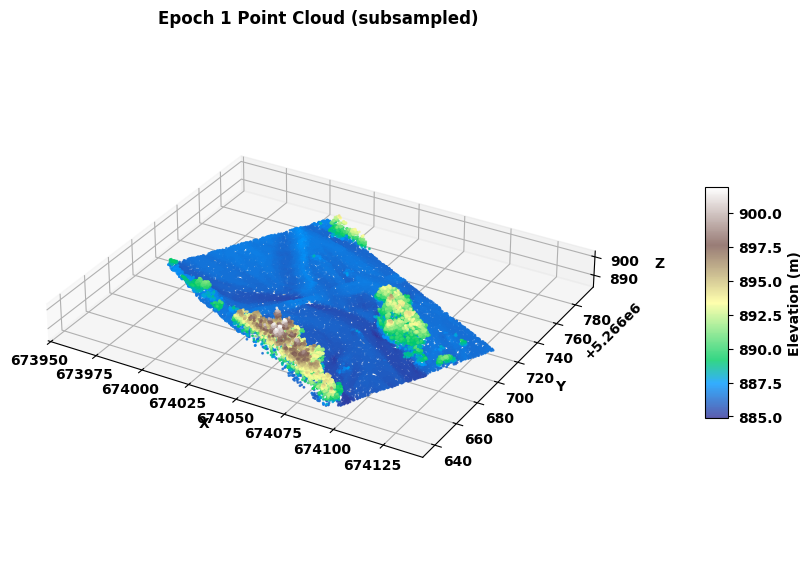

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator 

subset = epoch1.cloud[::100]
x = subset[:, 0]
y = subset[:, 1]
z = subset[:, 2]
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
scatter = ax.scatter(x, y, z, c=z, cmap='terrain', s=1, alpha=0.8)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Epoch 1 Point Cloud (subsampled)")
ax.set_aspect('equal')
ax.zaxis.set_major_locator(MaxNLocator(nbins=2))
fig.colorbar(scatter, ax=ax, shrink=0.3, aspect=10, label='Elevation (m)', pad=0.15)

plt.show()

## Bi-temporal analysis using M3C2

The analysis of point cloud distances is executed on so-called *core points* ([Lague et al., 2013](#References)). These could be, e.g., one of the input point clouds, a subsampled version thereof, points in an equidistant grid, etc. Here, we choose a subsampling by taking every 50th point of the reference point cloud.

In [14]:
corepoints = epoch1.cloud[::50]

Now we are ready to set up and run the M3C2 algorithm. Let's take a closer look at the parameters:

*   `epochs`: This is a tuple containing the two point clouds (from different times) that we want to compare. `epoch1` is treated as the reference cloud, and `epoch2` as the target cloud.
*   `corepoints`: These are the specific points at which the M3C2 distances will be calculated. The algorithm will compute one distance value for each point in this array.
*   `cyl_radius`: This is the projection cylinder radius. For each core point, M3C2 projects the local neighborhood of points from both clouds into a cylinder to calculate the average distance. This radius defines the size of the cylinder.
*   `normal_radii`: This is a list of radii used for calculating the surface normal at each core point. 

In [ ]:
m3c2 = py4dgeo.M3C2(
    epochs=(epoch1, epoch2),
    corepoints=corepoints,
    cyl_radius=2.0,
    normal_radii=[0.5, 1.0, 1.5, 2.0],
)

distances, uncertainties = m3c2.run()

[2026-05-08 23:57:08][INFO] Building KDTree structure with leaf parameter 10
[2026-05-08 23:57:11][INFO] Building KDTree structure with leaf parameter 10


In [16]:
distances

array([-0.02623343,  0.00132395,  0.00197531, ...,  0.05216049,
       -0.17835224, -0.17584255], shape=(65246,))

## Visualization
Now that we have the distances, the best way to interpret them is to visualize them on the point cloud. We will create a 3D scatter plot of our core points, and use the M3C2 distances to color each point.

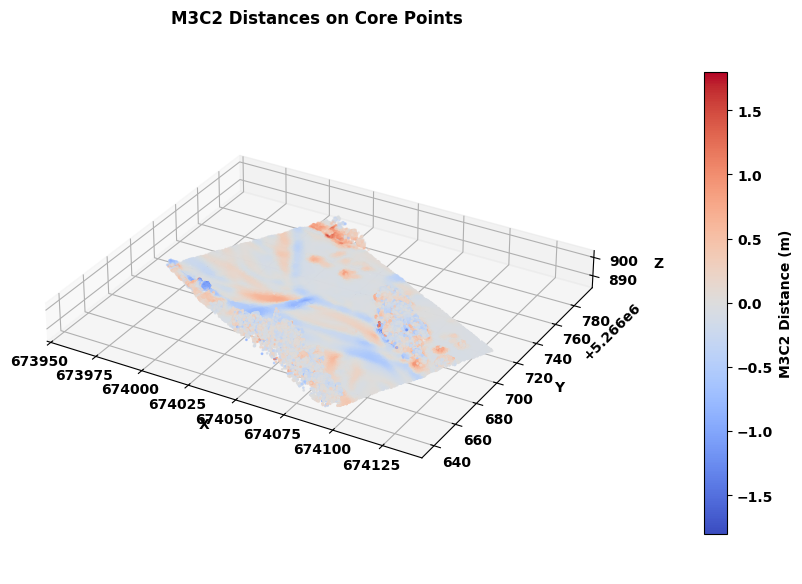

In [ ]:
vmax = 1.8
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
sc = ax.scatter(
    corepoints[:, 0], 
    corepoints[:, 1], 
    corepoints[:, 2], 
    c=distances, 
    cmap='coolwarm',
    s=1,
    vmin=-vmax,
    vmax=vmax
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.15)
cbar.set_label('M3C2 Distance (m)')
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("M3C2 Distances on Core Points")
ax.set_aspect('equal', 'box')
ax.zaxis.set_major_locator(MaxNLocator(nbins=2))
plt.show()

## References
* Lague, D., Brodu, N., & Leroux, J. (2013). Accurate 3D comparison of complex topography with terrestrial laser scanner: Application to the Rangitikei canyon (N-Z). ISPRS Journal of Photogrammetry and Remote Sensing, 82, pp. 10-26. doi: [10.1016/j.isprsjprs.2013.04.009](https://doi.org/10.1016/j.isprsjprs.2013.04.009)."
  